# Shadow Weights on Depth 2

> **Overview.** 07's LTUs, with depth-1 LTUs that can take their shadow weight on a depth-2 LTU instead of an output:
> does serving a depth-2 LTU, drawn at random or by how useful it is, find the target network sooner?

The step after `07_two_hidden_layers.ipynb`, which reaches the reference but slowly: depth-2 target LTUs are found only
after the depth-1 target LTUs they read, and the last depth-1 target LTUs found are those that few or no outputs read,
so that only depth 2 uses them. A depth-1 LTU's shadow weight on an output gives it little push toward such a feature;
one on a depth-2 LTU passes back that LTU's error.

**Problem.** $N = 1000$ standard normal inputs. Two hidden layers of 8 target LTUs each, with random $\pm 1$ weights
and threshold 0, giving $\pm 1$: a depth-1 target LTU reads 10 inputs drawn at random, and a depth-2 target LTU reads 5
inputs and 5 depth-1 target LTUs drawn at random. 10 outputs, each reading 2 inputs and 2 target LTUs of each depth drawn
at random, with random weights $\pm 1 / \sqrt{6}$, plus $N(0, 0.1^2)$ noise. The best possible RMSE is 0.1 (dotted line). Each seed
has its own target network.

**Learner.** As in `07_two_hidden_layers.ipynb`: the linear learner, a bias, and 16 LTUs of each depth, standardized
online and computed depth by depth, with network Autostep; the LTUs are added after 100k steps, each reading 1 to 20
sources drawn by its shadow weight, with fast learning, growth, and search every 10k steps (depth-2 LTUs that barely
read depth 1 moving to depth 1); everything learns for 600k steps after the LTUs are added. What changes is the shadow
weights. Every new LTU, whether added or rewired by search, draws its shadow weight, +1 or -1 by slot: a depth-2 LTU on
an output drawn at random, and a depth-1 LTU, with equal chance, on an output drawn at random or on a depth-2 LTU. A
depth-2 LTU reads the depth-1 LTUs with shadow weights on it, connections it lacks starting at weight 0 with step-size
0.03 (when it is replaced, the new LTU in its slot reads them too). As on outputs, a shadow weight stands in for the
real weight in the backward pass while that is smaller than 1 in magnitude, so the error that reaches a depth-2 LTU,
through its own shadow weight while that is in use, passes on to the depth-1 LTUs with shadow weights on it. An LTU's
seeds and fast-learning signs come from its shadow target's weights on the sources it may read: for a depth-1 LTU with
a shadow weight on a depth-2 LTU, that LTU's weights on the inputs, which are nonzero only on those it reads, so the
depth-1 LTU reads at most that many. Depth-2 LTUs are rewired before depth-1 LTUs, so that depth-1 LTUs draw on new
depth-2 LTUs' weights. When a depth-2 LTU moves to depth 1, the shadow weights on it stay with its slot.

**Runs.** 5 seeds per configuration; the same seed gives every run the same target network and samples. Growth with
fast search every 10k steps, with shadow weights: *on outputs only* (baseline: 07's method, every new LTU drawing a new
shadow output); *on depth-2 LTUs too, drawn at random* (proposed); *on depth-2 LTUs too, drawn by usefulness*
(proposed): a depth-2 LTU is drawn with probability proportional to its sum of outgoing weight magnitudes (what search
keeps LTUs by), so never one being replaced, and at random if all are 0, as when the LTUs are first added. *LTUs wired
like the target network* (reference) and *linear learner* (baseline), as in 07. Curves are the mean over seeds of the
RMSE over the 10 outputs, averaged over windows of 1k steps; final performance is the RMSE over the last 10% of steps.


In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 1000
N_PER_DEPTH = 8                      # target LTUs per hidden layer
N_SOURCES = 10                       # sources each target LTU reads, split equally over the depths below it
N_OUTPUTS = 10
OUTPUT_FAN_IN = 6                    # sources each output reads, split equally over the inputs and the 2 hidden layers
NOISE_STD = 0.1                      # observation noise on each output: the RMSE floor

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the hidden units
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
N_LTUS = 32                          # hidden LTUs, the first half of depth 1 and the second of depth 2
MAX_FAN_IN = 20                      # LTUs with sampled inputs read 1 to MAX_FAN_IN of them
REPLACED = 4                         # LTUs replaced at each search step, those with the smallest sum of |outgoing weights|
FAST_STEP_SIZE = 3e-2                # initial step-size of the input weights of LTUs that learn fast
GROW_Z = 6.0                         # an LTU connects a source whose gradient sum is this many RMS above the rest
FLAT_SHARE = 0.1                     # a depth-2 LTU with less than this share of its input |weights| on depth-1 LTUs
                                     # acts as a depth-1 LTU

# --- Experiment ---
LINEAR_STEPS = 100_000               # the linear learner learns alone for this many steps, then the LTUs are added
NUM_STEPS = 600_000                  # steps after the LTUs are added
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 5
PERIOD = 10_000                      # steps between search steps


## Target

In [3]:
class Target(NamedTuple):
    w: jax.Array                # (2 * N_PER_DEPTH, N_INPUTS + 2 * N_PER_DEPTH): the target LTUs' weights over [inputs,
                                # target LTUs], +-1 on the sources they read, 0 elsewhere; the first N_PER_DEPTH have depth 1
    out: jax.Array              # (N_OUTPUTS, N_INPUTS + 2 * N_PER_DEPTH): the outputs' weights over [inputs, target
                                # LTUs], +-1/sqrt(OUTPUT_FAN_IN) on the sources they read


def make_target(key):
    # A target network: each depth-1 target LTU reads N_SOURCES inputs, each depth-2 one N_SOURCES / 2 inputs and
    # N_SOURCES / 2 depth-1 target LTUs, and each output OUTPUT_FAN_IN / 3 inputs and target LTUs of each depth, all
    # drawn at random, with random +-1 weights (the outputs' scaled by 1 / sqrt(OUTPUT_FAN_IN)).
    k = jax.random.split(key, 8)
    n = N_PER_DEPTH
    pick = lambda key, shape, count: jnp.argsort(jnp.argsort(jax.random.uniform(key, shape))) < count  # per row
    inputs = jnp.concatenate([pick(k[0], (n, N_INPUTS), N_SOURCES), pick(k[1], (n, N_INPUTS), N_SOURCES // 2)])
    hidden = jnp.zeros((2 * n, 2 * n), bool).at[n:, :n].set(pick(k[2], (n, n), N_SOURCES // 2))
    w = jax.random.rademacher(k[3], (2 * n, N_INPUTS + 2 * n), dtype=float) * jnp.concatenate([inputs, hidden], 1)
    reads = jnp.concatenate([pick(k[7], (N_OUTPUTS, N_INPUTS), OUTPUT_FAN_IN // 3),
                             pick(k[4], (N_OUTPUTS, n), OUTPUT_FAN_IN // 3), pick(k[5], (N_OUTPUTS, n), OUTPUT_FAN_IN // 3)], 1)
    out = jax.random.rademacher(k[6], reads.shape, dtype=float) * reads / np.sqrt(OUTPUT_FAN_IN)
    return Target(w, out)


def sample(target, key):
    # One input and its noisy targets, the target LTUs computed depth by depth.
    x_key, noise_key = jax.random.split(key)
    x = jax.random.normal(x_key, (N_INPUTS,))
    s = jnp.zeros(2 * N_PER_DEPTH)
    for rows in (slice(0, N_PER_DEPTH), slice(N_PER_DEPTH, None)):
        s = s.at[rows].set(jnp.where(target.w[rows] @ jnp.concatenate([x, s]) > 0, 1.0, -1.0))
    return x, target.out @ jnp.concatenate([x, s]) + NOISE_STD * jax.random.normal(noise_key, (N_OUTPUTS,))

## Learner

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the hidden units, each shaped (units,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each hidden unit, and of g * h
    error_h_mean: jax.Array


HALF = N_LTUS // 2
DEPTHS = (slice(0, HALF), slice(HALF, N_LTUS))   # the hidden units of depth 1 and of depth 2
# LOWER[u, j]: whether hidden unit u may read source j of [inputs, hidden units, 1]: every input and the bias, and the
# hidden units of lower depth.
LOWER = jnp.ones((N_LTUS, N_INPUTS + N_LTUS + 1), bool).at[:, N_INPUTS:-1].set(
    (jnp.arange(N_LTUS) >= HALF)[:, None] & (jnp.arange(N_LTUS) < HALF)[None])


class Net(NamedTuple):
    # w['hidden'] is the hidden units' weights over [inputs, hidden units, 1 (the bias)], of which they read those in
    # `reads`; w['output'] is the outputs' weights over [inputs (the linear learner), the hidden units, 1]. `mask` says
    # which of the outputs' connections exist; the hidden units' are switched on when the units are added.
    w: dict                     # {'hidden': (N_LTUS, N_INPUTS + N_LTUS + 1), 'output': (N_OUTPUTS, N_INPUTS + N_LTUS + 1)}
    reads: jax.Array            # shaped like w['hidden']
    mask: jax.Array             # shaped like w['output']
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (N_OUTPUTS, N_LTUS): each hidden unit's shadow weight on an output, and
    shadow_hidden: jax.Array    # (N_LTUS, N_LTUS) on a depth-2 unit (rows): +-1 on one output or depth-2 unit, 0 elsewhere
    candidates: jax.Array       # (N_LTUS, N_INPUTS + N_LTUS): sum of dL/dz * source since each unit's last new connection


def active(net):
    # Which slots hold a hidden unit.
    return jnp.any(net.shadow != 0, 0) | jnp.any(net.shadow_hidden != 0, 0)


def shadow_target_weights(net):
    # Shaped like w['hidden']: each hidden unit's shadow weight times its shadow target's weights on the sources it may
    # read (an output's weight on an input is the linear learner's), 0 elsewhere and on the bias.
    targets = net.shadow.T @ net.w['output'] + net.shadow_hidden.T @ (net.w['hidden'] * net.reads)
    return targets.at[:, -1].set(0.0) * LOWER


def usefulness(net):
    # Each hidden unit's sum of |outgoing weights|, to the outputs and to depth-2 units.
    return (jnp.abs(net.w['output'][:, N_INPUTS:-1]).sum(0)
            + jnp.abs(net.w['hidden'][:, N_INPUTS:-1] * net.reads[:, N_INPUTS:-1]).sum(0))


def init_net(key, target, units, sampled):
    # `units` hidden units (the rest of the N_LTUS slots left empty), each pair of a depth wired like one target LTU of
    # that depth in turn, reading its inputs and the depth-1 units wired like its depth-1 target LTUs and the bias,
    # with LeCun uniform weights over their fan-in; their shadow weights +1 and -1 alternately, each on an output drawn
    # at random among those that read its target LTU (among all outputs if sampled, or if none does); every other
    # weight at 0.
    w_key, out_key = jax.random.split(key)
    slot = jnp.arange(N_LTUS)
    assigned = slot // HALF * N_PER_DEPTH + slot % HALF // 2 % N_PER_DEPTH   # the target LTU each unit is wired like
    target_reads = target.w[assigned] != 0
    wired = jnp.concatenate([target_reads[:, :N_INPUTS], target_reads[:, N_INPUTS:][:, assigned],
                             jnp.ones((N_LTUS, 1), bool)], 1)
    reads = wired & LOWER
    fan_in = reads[:, :-1].sum(1, keepdims=True)
    readers = (target.out[:, N_INPUTS + assigned] != 0) | sampled
    readers = readers | ~readers.any(0)
    shadow_out = jnp.argmax(jnp.where(readers, jax.random.gumbel(out_key, readers.shape), -jnp.inf), 0)
    sign = jnp.where(slot < units, jnp.where(slot % 2 == 0, 1.0, -1.0), 0.0)
    shadow = (jnp.arange(N_OUTPUTS)[:, None] == shadow_out) * sign
    mask = jnp.ones((N_OUTPUTS, N_INPUTS + N_LTUS + 1), bool).at[:, N_INPUTS:-1].set(False)
    w = {'hidden': (jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0)
                    * jnp.sqrt(3.0 / fan_in) * reads).at[:, -1].set(0.0),
         'output': jnp.zeros((N_OUTPUTS, N_INPUTS + N_LTUS + 1))}
    stats = Stats(jnp.full(N_LTUS, 0.5), jnp.zeros(N_LTUS), jnp.zeros(N_LTUS))
    return Net(w, reads, mask, OPTIMIZER.init(w), stats, shadow, jnp.zeros((N_LTUS, N_LTUS)),
               jnp.zeros((N_LTUS, N_INPUTS + N_LTUS)))


def redraw(net, key, replaced, consumers):
    # The `replaced` hidden units' new shadow weights, +1 or -1 by slot: each on an output drawn at random, or, with
    # equal chance for a depth-1 unit if consumers, on a depth-2 unit, drawn at random if consumers is 1, and if it is 2
    # with probability proportional to its sum of |outgoing weights| (taken as 0 for those being replaced), at random if
    # all are 0.
    layer_key, output_key, unit_key = jax.random.split(key, 3)
    slot = jnp.arange(N_LTUS)
    on_hidden = (consumers > 0) & (slot < HALF) & (jax.random.uniform(layer_key, (N_LTUS,)) < 0.5)
    weight = jnp.where(replaced, 0.0, usefulness(net))[HALF:]
    logits = jnp.where((consumers == 2) & (weight.sum() > 0), jnp.log(weight), 0.0)
    unit = HALF + jnp.argmax(logits[:, None] + jax.random.gumbel(unit_key, (HALF, N_LTUS)), 0)
    output = jax.random.randint(output_key, (N_LTUS,), 0, N_OUTPUTS)
    sign = jnp.where(slot % 2 == 0, 1.0, -1.0)
    shadow = (jnp.arange(N_OUTPUTS)[:, None] == output) * jnp.where(on_hidden, 0.0, sign)
    shadow_hidden = (slot[:, None] == unit) * jnp.where(on_hidden, sign, 0.0)
    return net._replace(shadow=jnp.where(replaced, shadow, net.shadow),
                        shadow_hidden=jnp.where(replaced, shadow_hidden, net.shadow_hidden))


def rewire(net, key, replaced, rows):
    # The `rows` hidden units (a mask over slots, among the `replaced` units) each read 1 to MAX_FAN_IN sources
    # (uniform, but no more than their shadow target has nonzero weights on) and the bias, the sources, inputs and
    # lower-depth units alike, drawn without replacement with probability proportional to the square of their shadow
    # target's weight on them (Gumbel top-k), with fresh LeCun uniform weights over their fan-in, output weights at 0,
    # and fresh statistics, Autostep state and gradient sums; the other units' connections from the replaced units are
    # cut. Then every unit reads the units with shadow weights on it, connections it lacks starting at weight 0 with
    # step-size FAST_STEP_SIZE.
    fan_key, draw_key, w_key = jax.random.split(key, 3)
    cut = jnp.zeros_like(net.reads).at[:, N_INPUTS:-1].set(replaced[None])   # connections from the replaced units
    weights = jnp.where(cut, 0.0, shadow_target_weights(net))[:, :-1]
    fan_in = jnp.minimum(jax.random.randint(fan_key, (N_LTUS, 1), 1, MAX_FAN_IN + 1),
                         (weights != 0).sum(1, keepdims=True))
    scores = jnp.log(weights ** 2) + jax.random.gumbel(draw_key, weights.shape)
    reads = jnp.append(jnp.argsort(jnp.argsort(-scores)) < fan_in, jnp.ones((N_LTUS, 1), bool), axis=1)
    hidden = (jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / jnp.maximum(fan_in, 1))
              * reads)
    changed = rows[:, None] | cut
    reads = jnp.where(changed, reads, net.reads)
    served = jnp.zeros_like(reads).at[:, N_INPUTS:-1].set(net.shadow_hidden != 0) & ~reads
    where = {'hidden': changed,
             'output': jnp.concatenate([jnp.zeros(N_INPUTS, bool), rows, jnp.zeros(1, bool)])[None]}
    reset = lambda tree, fresh: jax.tree.map(lambda m, a, b: jnp.where(m, a, b), where, fresh, tree)
    w = reset(net.w, {'hidden': hidden.at[:, -1].set(0.0), 'output': jnp.zeros_like(net.w['output'])})
    zeros = jax.tree.map(jnp.zeros_like, net.w)
    beta = reset(net.opt.beta, jax.tree.map(lambda a: a + net.opt.init_beta, zeros))
    beta = {**beta, 'hidden': jnp.where(served, jnp.log(FAST_STEP_SIZE), beta['hidden'])}
    opt = net.opt._replace(beta=beta, h=reset(net.opt.h, zeros), v=reset(net.opt.v, zeros))
    stats = Stats(*(jnp.where(rows, fresh, old) for fresh, old in zip((0.5, 0.0, 0.0), net.stats)))
    return net._replace(w=w, reads=reads | served, opt=opt, stats=stats,
                        candidates=jnp.where(changed[:, :-1], 0.0, net.candidates))


def speed_up(net, replaced):
    # The `replaced` hidden units' weights keep their magnitudes but take the signs of their shadow weight times their
    # shadow target's weights on those sources (0 where that weight is 0), and the step-sizes of all their weights but
    # the bias's start at FAST_STEP_SIZE.
    sources = net.reads.at[:, -1].set(False) & replaced[:, None]
    hidden = jnp.where(sources, jnp.abs(net.w['hidden']) * jnp.sign(shadow_target_weights(net)), net.w['hidden'])
    beta = jnp.where(sources, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': hidden}, opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}))


def grow(net):
    # Each hidden unit whose largest gradient sum, over the sources it may read but does not, is more than GROW_Z times
    # their root mean square connects that source, at weight 0 with step-size FAST_STEP_SIZE, and restarts its sums.
    unread = LOWER[:, :-1] & ~net.reads[:, :-1]
    sums = jnp.where(unread, jnp.abs(net.candidates), 0.0)
    rms = jnp.sqrt(jnp.sum(sums ** 2, 1) / unread.sum(1))
    best = jnp.argmax(sums, 1)
    grows = (jnp.max(sums, 1) > GROW_Z * rms) & active(net)
    new = (jnp.arange(N_INPUTS + N_LTUS + 1) == best[:, None]) & grows[:, None]
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': jnp.where(new, 0.0, net.w['hidden'])}, reads=net.reads | new,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}),
                        candidates=jnp.where(grows[:, None], 0.0, net.candidates))


def learn(net, x, y):
    # One online network-Autostep update on half the squared error summed over the outputs, the hidden units computed
    # depth by depth, each shadow weight standing in for its hidden unit's weight to that output or depth-2 unit in the
    # backward pass while the real one is smaller in magnitude, the other weights used as they are. Returns the new
    # network and the squared error on this sample averaged over the outputs, before learning from it, and adds
    # dL/dz * source to each hidden unit's gradient sums. `probe` is zero; its gradients are the error arriving at each
    # hidden unit and dL/dz.

    def loss_fn(w, probe):
        w = {'hidden': w['hidden'] * net.reads, 'output': w['output'] * net.mask}

        def back(shadow, real):
            # The weights used in the backward pass: each shadow weight while the real one is smaller in magnitude.
            return jax.lax.stop_gradient(jnp.where((shadow != 0) & (jnp.abs(real) < 1.0), shadow, real))

        hidden_back = back(net.shadow_hidden, w['hidden'][:, N_INPUTS:-1])
        a, means, hs = jnp.zeros(N_LTUS), [], []
        for rows in DEPTHS:
            through_back = hidden_back[rows] @ a
            z = (w['hidden'][rows] @ jax.lax.stop_gradient(jnp.concatenate([x, a, jnp.ones(1)])) + through_back
                 - jax.lax.stop_gradient(through_back))
            b = ltu(z + probe[1][rows])
            mean = net.stats.hidden_mean[rows] + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean[rows])
            h = standardize(b, mean, net.stats.error_mean[rows], net.stats.error_h_mean[rows])
            a = a.at[rows].set(h + probe[0][rows])
            means.append(mean)
            hs.append(jax.lax.stop_gradient(h))
        source = jax.lax.stop_gradient(jnp.concatenate([x, a, jnp.ones(1)]))
        through_back = (back(net.shadow, w['output'][:, N_INPUTS:-1]) * net.mask[:, N_INPUTS:-1]) @ a
        prediction = w['output'] @ source + through_back - jax.lax.stop_gradient(through_back)
        return 0.5 * jnp.sum((prediction - y) ** 2), (source, jnp.concatenate(hs), jnp.concatenate(means))

    (loss, (source, h, mean)), (grads, error) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(net.w, (jnp.zeros(N_LTUS),) * 2)
    grads = {'hidden': grads['hidden'] * net.reads, 'output': grads['output'] * net.mask}
    error, dz = error
    sources = {'hidden': source[None] * net.reads, 'output': source[None] * net.mask}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats,
                        candidates=net.candidates + dz[:, None] * source[:-1]), 2 * loss / N_OUTPUTS

## Training

In [5]:
def swap(net, i, j):
    # Slots i and j exchange their units, but the shadow weights on depth-2 slot j stay on it; the unit arriving at
    # depth-1 slot i loses its connections from hidden units.
    perm = jnp.arange(N_LTUS).at[i].set(j).at[j].set(i)
    cols = jnp.concatenate([jnp.arange(N_INPUTS), N_INPUTS + perm, jnp.array([N_INPUTS + N_LTUS])])
    tree = lambda t: {'hidden': t['hidden'][perm][:, cols], 'output': t['output'][:, cols]}
    net = net._replace(w=tree(net.w), reads=net.reads[perm][:, cols], mask=net.mask[:, cols],
                       opt=net.opt._replace(beta=tree(net.opt.beta), h=tree(net.opt.h), v=tree(net.opt.v)),
                       stats=Stats(*(a[perm] for a in net.stats)), shadow=net.shadow[:, perm],
                       shadow_hidden=net.shadow_hidden[:, perm],
                       candidates=net.candidates[perm][:, cols[:-1]])
    cut = jnp.zeros_like(net.reads).at[i, N_INPUTS:-1].set(True)
    zero = lambda t: {**t, 'hidden': jnp.where(cut, 0.0, t['hidden'])}
    beta = jnp.where(cut, net.opt.init_beta, net.opt.beta['hidden'])
    return net._replace(w=zero(net.w), reads=net.reads & ~cut,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}, h=zero(net.opt.h), v=zero(net.opt.v)))


def train(net, key, target, sampled, period, fast, grows, consumers, add_step, num_steps):
    # num_steps online network-Autostep steps on samples from `target`, the hidden units added at add_step (first given
    # new shadow weights, on depth-2 units too as `consumers` says, and rewired, if sampled), and every `period` steps
    # after that (never if period is 0) the REPLACED of them with the smallest sum of |outgoing weights| given new
    # shadow weights and rewired, after the strongest depth-2 unit acting as a depth-1 unit (if any) swaps slots with
    # the weakest depth-1 unit, if weaker; every unit added or rewired sped up if fast, and every WINDOW steps after the
    # units are added, each grows if grows (before any rewiring). Returns each window's mean squared error.
    wire_key, key = jax.random.split(key)

    def one_step(net, inputs):
        step, key = inputs
        x, y = sample(target, key)
        net = net._replace(mask=net.mask.at[:, N_INPUTS:-1].set((step >= add_step) & active(net)))
        return learn(net, x, y)

    def start(net, key, replaced, rewired):
        # The replaced units given new shadow weights and rewired (if rewired), and sped up (if fast), those of depth 2
        # first, so that depth-1 units with shadow weights on depth-2 units draw on their new weights.
        keys = jax.random.split(key, 3)
        net = jax.tree.map(lambda a, b: jnp.where(rewired, a, b), redraw(net, keys[0], replaced, consumers), net)
        for depth, depth_key in zip(DEPTHS[::-1], keys[1:]):
            rows = replaced & jnp.zeros(N_LTUS, bool).at[depth].set(True)
            net = jax.tree.map(lambda a, b: jnp.where(rewired, a, b), rewire(net, depth_key, replaced, rows), net)
            net = jax.tree.map(lambda a, b: jnp.where(fast, a, b), speed_up(net, rows), net)
        return net

    def window(net, inputs):
        index, key = inputs
        net, mse = jax.lax.scan(one_step, net, (index * WINDOW + jnp.arange(WINDOW), jax.random.split(key, WINDOW)))
        since_added = (index + 1) * WINDOW - add_step
        net = jax.tree.map(lambda a, b: jnp.where(grows & (since_added > 0), a, b), grow(net), net)
        due = (period > 0) & (since_added > 0) & (since_added % jnp.maximum(period, 1) == 0)
        outgoing = usefulness(net)
        links = jnp.abs(net.w['hidden'][:, :-1]) * net.reads[:, :-1]
        flat = (jnp.arange(N_LTUS) >= HALF) & active(net) & (links[:, N_INPUTS:].sum(1) < FLAT_SHARE * links.sum(1))
        mover = jnp.argmax(jnp.where(flat, outgoing, -jnp.inf))
        weak = jnp.argmin(jnp.where(active(net) & (jnp.arange(N_LTUS) < HALF), outgoing, jnp.inf))
        moved = due & flat.any() & (outgoing[mover] > outgoing[weak])
        net = jax.tree.map(lambda a, b: jnp.where(moved, a, b), swap(net, weak, mover), net)
        outgoing = jnp.where(moved, outgoing.at[weak].set(outgoing[mover]).at[mover].set(-1.0), outgoing)
        weakest = jnp.argsort(jnp.where(active(net), outgoing, jnp.inf))[:REPLACED]
        searched = start(net, jax.random.fold_in(wire_key, index), jnp.zeros(N_LTUS, bool).at[weakest].set(True), True)
        return jax.tree.map(lambda a, b: jnp.where(due, a, b), searched, net), mse.mean()

    n, added = num_steps // WINDOW, add_step // WINDOW
    index, keys = jnp.arange(n), jax.random.split(key, n)
    net, before = jax.lax.scan(window, net, (index[:added], keys[:added]))
    net = start(net, wire_key, active(net), sampled)
    return jnp.concatenate([before, jax.lax.scan(window, net, (index[added:], keys[added:]))[1]])


def run(configs):
    # Each (units, sampled, period, fast, grows, consumers) of configs: `units` hidden LTUs reading sampled inputs if
    # sampled, searched every `period` steps (0: never), and wired like the target network otherwise (no LTUs: the
    # linear learner alone), learning fast if fast, growing if grows, and with shadow weights on depth-2 LTUs too if
    # consumers (1: drawn at random, 2: by usefulness), each on N_SEEDS seeds, vmapped together. Seed s gives every run
    # the same target network and samples. Returns {config: the RMSE of each window from step 1, shaped (seed, window)}.
    units, sampled, period, fast, grows, consumers, seed = (jnp.array(v) for v in zip(*[(*c, s) for c in configs
                                                                                        for s in range(N_SEEDS)]))
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    targets = jax.vmap(make_target)(keys(2))
    nets = jax.vmap(init_net)(keys(0), targets, units, sampled)
    train_all = jax.jit(jax.vmap(lambda n, k, t, s, p, f, g, c: train(n, k, t, s, p, f, g, c, LINEAR_STEPS,
                                                                      LINEAR_STEPS + NUM_STEPS)))
    mse = train_all(nets, keys(1), targets, sampled, period, fast, grows, consumers)
    return dict(zip(configs, np.sqrt(np.asarray(mse)).reshape(len(configs), N_SEEDS, -1)))

## Runs

In [6]:
LINEAR, REFERENCE = (0, False, 0, False, False, 0), (N_LTUS, False, 0, True, False, 0)
OUTPUTS, AT_RANDOM, BY_USEFULNESS = ((N_LTUS, True, PERIOD, True, True, consumers) for consumers in (0, 1, 2))
started = perf_counter()
rmse = run([OUTPUTS, AT_RANDOM, BY_USEFULNESS, REFERENCE, LINEAR])
print(f'{len(rmse) * N_SEEDS} runs in {perf_counter() - started:.0f}s')

25 runs in 92s


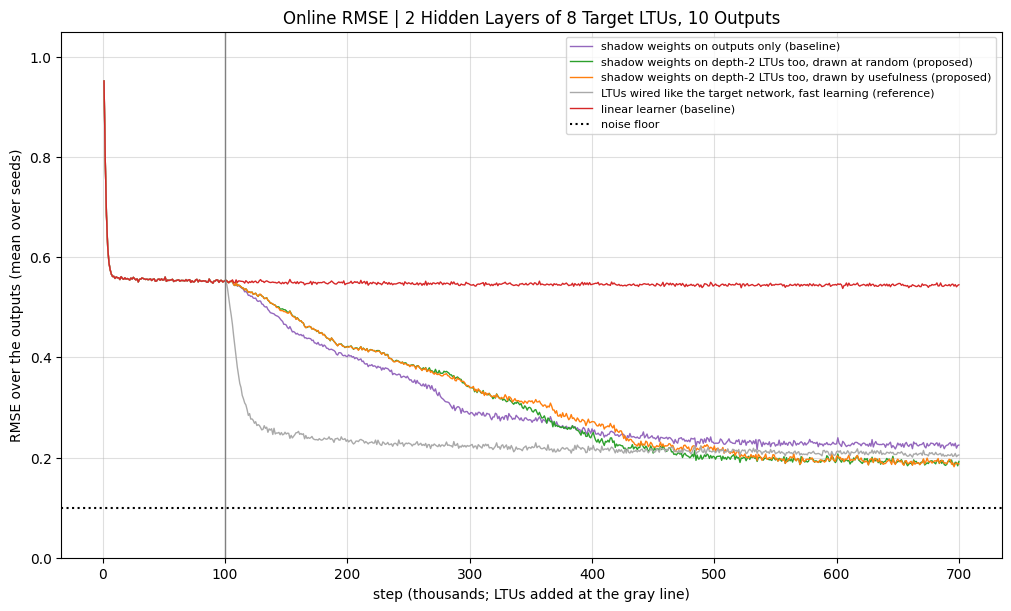

In [7]:
STEPS = (np.arange((LINEAR_STEPS + NUM_STEPS) // WINDOW) + 1) * WINDOW
METHODS = {'shadow weights on outputs only (baseline)': (OUTPUTS, 'tab:purple'),
           'shadow weights on depth-2 LTUs too, drawn at random (proposed)': (AT_RANDOM, 'tab:green'),
           'shadow weights on depth-2 LTUs too, drawn by usefulness (proposed)': (BY_USEFULNESS, 'tab:orange'),
           'LTUs wired like the target network, fast learning (reference)': (REFERENCE, 'darkgray'),
           'linear learner (baseline)': (LINEAR, 'tab:red')}

fig, ax = plt.subplots(figsize=(10, 6), layout='constrained')
for label, (config, color) in METHODS.items():
    ax.plot(STEPS / 1000, rmse[config].mean(0), color=color, lw=1, label=label)
ax.axvline(LINEAR_STEPS / 1000, color='gray', lw=1)
ax.axhline(NOISE_STD, color='black', ls=':', label='noise floor')
ax.set(xlabel='step (thousands; LTUs added at the gray line)', ylabel='RMSE over the outputs (mean over seeds)',
       ylim=(0, 1.05), title=f'Online RMSE | 2 Hidden Layers of {N_PER_DEPTH} Target LTUs, {N_OUTPUTS} Outputs')
ax.grid(alpha=0.4)
ax.legend(fontsize=8)
plt.show()

## Results

5 seeds per configuration. The notebook takes about 2 minutes.

- **Shadow weights on depth-2 LTUs reach the lowest RMSE, on every seed**: 0.191 over the last 10% of steps, drawn at
  random or by usefulness alike, against 0.225 with shadow weights on outputs only (2 of 5 seeds stuck at 0.27 to 0.29),
  0.207 for LTUs wired like the target network (still falling) and 0.54 for the linear learner. 07's method needed 2M
  steps for 0.193.
- **They are slower at first**: above the baseline until about step 400k, since half the depth-1 LTUs no longer push
  toward the features the outputs read. They reach 0.25 a median 288k steps after the LTUs are added when drawn at random
  (203k to 364k) and 325k by usefulness (204k to 412k); the baseline 274k (177k to never; 2 seeds never); the reference
  27k.
- **What they find** (checked separately, at the end; a target LTU is *found* when some LTU's output has |correlation|
  above 0.9 with it): every depth-1 target LTU and 93% of the depth-2 ones, against 95% and 68% with shadow weights on
  outputs only and 100% and 82% for the reference.
- **Drawing by usefulness rarely acts**: only when search replaces a depth-1 LTU that then draws depth 2, 8 to 22 times
  per run (search mostly replaces depth-2 LTUs); the other depth-1 LTUs keep the depth-2 LTU drawn at random when the
  LTUs were added.